# 1차 필터(욕설/스팸) 분류기 벤치마크 — 후보 모델 비교

**스파이크/평가용 코드입니다. 프로덕션 코드가 아닙니다.**

`classifier_benchmark.py`(모델 로딩 + 벤치마크 실행 + 결과 집계 로직만 담은 라이브러리 모듈)를
import해서, 후보 분류기들을 실제로 로드하고 지연시간·클래스별 recall을 비교한다.

`classifier_benchmark.py`는 스크립트가 아니라 모듈이라 그 자체를 실행하는 게 아니라 이 노트북에서
`benchmark_model()` / `run_all()`을 직접 호출한다. 후보를 바꾸려면 아래 "3. 후보 모델별 벤치마크 실행"
셀의 `ALL_MODELS` 딕셔너리를 수정하면 된다(`classifier_benchmark.CANDIDATE_MODELS` /
`model_registry.CLASSIFIER_MODELS` 참고).

이 노트북은 코드만 작성한 상태이고 셀을 실행하지 않았다 — 실행은 로컬(RTX 4070) 환경에서 진행한다.

In [1]:
%pip install -q -r ../requirements-test.txt

Note: you may need to restart the kernel to use updated packages.


## 1. 모듈 import

`classifier_benchmark.py`에서 벤치마크 실행/집계에 필요한 것만 가져온다. 후보 모델 딕셔너리
(`CANDIDATE_MODELS`, `model_registry.CLASSIFIER_MODELS`)는 다음 섹션에서 병합해 쓴다.

In [2]:
from classifier_benchmark import (
    BenchResult,
    CANDIDATE_MODELS,
    CANDIDATE_NOTES,
    Sample,
    benchmark_model,
    print_report,
    run_all,
)
from model_registry import CLASSIFIER_MODELS

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. 테스트 샘플 — 우회 패턴 포함 확장 (정상/악성, 200건 이상)

`chat_agent.ipynb`에 있던 기존 샘플(정상 3건 : 악성 2건, 스팸 1건 — "품절이요" 반복 게시)을 베이스로
확장한다. 다만 두 가지를 반영했다:

- **스팸 라벨은 이번 샘플셋에서 제외한다.** `classifier_benchmark.py`가 로드하는 건 순수 텍스트
  분류기(정상/악성 2-way)라서, rate-limit 기반 `SpamDetector`(`chat_agent.py`)가 담당하는 스팸 여부를
  애초에 예측할 수 없다 — 포함시켜봐야 모든 후보가 구조적으로 100% 틀리는 라벨이 될 뿐이다
  (`classifier_benchmark.py`의 `DEFAULT_SAMPLES` 주석에도 같은 이유로 명시돼 있다).
- **실제 방송 채팅 로그가 아직 없어서**, 원본 샘플의 정상:악성 비율(3:2)을 그대로 유지한 채 문장
  다양성만 늘렸다. 실제 로그가 확보되면 이 비율부터 재조정해야 한다.

우회 패턴(초성체 / 띄어쓰기 우회 / 자모·웃음 반복)은 실제 문장을 손으로 200개 넘게 쓰는 대신,
아래에서 규칙 기반으로 생성한다.

In [3]:
# 한글 음절 -> 초성만 추출(초성체 우회 재현용). 유니코드 완성형 한글 공식:
# code = (초성index * 588) + (중성index * 28) + 종성index, 0xAC00('가')부터 시작.
_CHOSUNG_LIST = [
    "ㄱ", "ㄲ", "ㄴ", "ㄷ", "ㄸ", "ㄹ", "ㅁ", "ㅂ", "ㅃ", "ㅅ",
    "ㅆ", "ㅇ", "ㅈ", "ㅉ", "ㅊ", "ㅋ", "ㅌ", "ㅍ", "ㅎ",
]


def to_chosung(text: str) -> str:
    """완성형 한글 음절을 초성만 남긴 문자열로 바꾼다(예: "미친놈아" -> "ㅁㅊㄴㅇ").

    한글 음절이 아닌 문자(공백 등)는 그대로 둔다. 실제 채팅에서 욕설 필터를
    피하려고 초성만 남기는 우회 패턴을 재현한다.
    """
    result = []
    for ch in text:
        code_point = ord(ch) - 0xAC00
        if 0 <= code_point <= 11171:
            result.append(_CHOSUNG_LIST[code_point // 588])
        else:
            result.append(ch)
    return "".join(result)


def to_spaced(text: str) -> str:
    """음절 사이에 공백을 넣는다(예: "병신같은게" -> "병 신 같 은 게") — 띄어쓰기 우회 재현."""
    return " ".join(text)


def with_laugh_suffix(text: str, repeat: int = 6) -> str:
    """문장 끝에 자모("ㅋ")를 반복 추가한다 — 조롱성 웃음으로 욕설/비하를 감추는 패턴 재현."""
    return text + "ㅋ" * repeat


# --- 정상 댓글 템플릿 21개 x 어미/이모지성 접미사 6개 = 126건 ---
_NORMAL_TEMPLATES = [
    "이 옷 진짜 예쁘네요 판매자님 감사합니다",
    "사이즈 잘 맞을까요",
    "색상 실물이 더 예쁘네요",
    "배송 빠르네요 감사합니다",
    "이전에 산 것도 좋았어요 재구매합니다",
    "핏이 너무 좋아요",
    "세탁 방법이 궁금해요",
    "방송 잘 보고 있습니다",
    "다음 방송 언제 하시나요",
    "포장 꼼꼼하게 잘 왔어요",
    "이 브랜드 처음 사보는데 기대되네요",
    "사진보다 실물이 더 좋아요",
    "이 가격에 이 퀄리티면 혜자에요",
    "구매하길 잘한 것 같아요",
    "판매자님 응대 친절하시네요",
    "품질 좋고 착용감도 편해요",
    "이 소재 계절에 잘 맞을 것 같아요",
    "라이브 진행 재밌게 잘 보고 있어요",
    "다른 색상도 예쁘네요",
    "필요했던 옷인데 마침 잘 샀어요",
    "구성품도 알차고 좋네요",
]
_NORMAL_SUFFIXES = ["", "!", "~", " ㅎㅎ", " 감사합니다", " 진짜 최고예요"]

# --- 악성(혐오/비방) 문장 템플릿 21개: 원문 + 웃음 접미사 버전 = 42건 ---
_ABUSIVE_SENTENCES = [
    "저런 걸 옷이라고 파네 진짜 미친놈인가",
    "여자가 무슨 명품을 입고 방송을 하냐 꼴값이네",
    "판매자 얼굴 보니까부터 실망이다",
    "그 가격에 그 퀄리티면 사기 아니냐",
    "목소리 진짜 짜증나게 하네",
    "누가 이런 걸 산다고 광고를 하냐 병신같은게",
    "얼굴만 믿고 방송하나 실력은 없네",
    "이 방송 진짜 노잼이다 꺼져라",
    "저 옷 입은 거 보니까 안목이 없네",
    "머리는 장식이냐 그것도 못 챙기고",
    "돈 받고 이렇게 파는 거 양심 있냐",
    "보고 있자니 한심하다 정말",
    "그 나이 먹고 저러고 사는 거 부끄럽지도 않냐",
    "재고 처리하려고 사기치는거 다 보인다",
    "누가 보면 대단한 브랜드인 줄 알겠네 우습다",
    "말하는 꼬라지 보니까 정떨어진다",
    "저러니 매출이 안 나오지 자업자득이다",
    "그 얼굴로 방송 나올 생각을 하다니 대단하다 진짜",
    "옷 고르는 눈이 그것밖에 안되나 답답하다",
    "누가 저런 말투로 방송을 하래 짜증나게",
    "실력도 없으면서 잘난 척은 다 하네",
]

# --- 짧은 비속어 어구 14개: 원문 + 초성체 + 띄어쓰기 우회 = 42건 ---
_SHORT_PROFANITY = [
    "미친놈아",
    "병신같은게",
    "재수없네",
    "정신나갔네",
    "한심하네",
    "역겹다",
    "구제불능이네",
    "무개념이네",
    "정신차려라",
    "생각이 없네",
    "부끄러운 줄 알아라",
    "낯짝이 두껍네",
    "싸구려 티 나네",
    "꼴보기 싫다",
]

print(
    f"정상 템플릿 {len(_NORMAL_TEMPLATES)}개 x 접미사 {len(_NORMAL_SUFFIXES)}개, "
    f"악성 문장 템플릿 {len(_ABUSIVE_SENTENCES)}개(x2 변형), "
    f"짧은 비속어 {len(_SHORT_PROFANITY)}개(x3 변형)"
)

정상 템플릿 21개 x 접미사 6개, 악성 문장 템플릿 21개(x2 변형), 짧은 비속어 14개(x3 변형)


In [4]:
SAMPLES_WITH_LABELS: list[Sample] = []
_next_id = 0


def _add(comment: str, label: str) -> None:
    global _next_id
    SAMPLES_WITH_LABELS.append((f"bench_user_{_next_id:04d}", comment, label))
    _next_id += 1


# 정상 126건 = 템플릿 21 x 접미사 6
for template in _NORMAL_TEMPLATES:
    for suffix in _NORMAL_SUFFIXES:
        _add(template + suffix, "정상")

# 악성(문장형) 42건 = 21 원문 + 21 웃음 접미사 버전(조롱성 "ㅋㅋㅋㅋㅋㅋ" 결합 우회)
for sentence in _ABUSIVE_SENTENCES:
    _add(sentence, "악성")
    _add(with_laugh_suffix(sentence), "악성")

# 악성(짧은 비속어) 42건 = 14 원문 + 14 초성체 우회 + 14 띄어쓰기 우회
for phrase in _SHORT_PROFANITY:
    _add(phrase, "악성")
    _add(to_chosung(phrase), "악성")
    _add(to_spaced(phrase), "악성")

from collections import Counter

label_counts = Counter(label for _, _, label in SAMPLES_WITH_LABELS)
print(f"총 샘플 수: {len(SAMPLES_WITH_LABELS)}")
print(f"라벨 분포: {dict(label_counts)}")
SAMPLES_WITH_LABELS[:5]

총 샘플 수: 210
라벨 분포: {'정상': 126, '악성': 84}


[('bench_user_0000', '이 옷 진짜 예쁘네요 판매자님 감사합니다', '정상'),
 ('bench_user_0001', '이 옷 진짜 예쁘네요 판매자님 감사합니다!', '정상'),
 ('bench_user_0002', '이 옷 진짜 예쁘네요 판매자님 감사합니다~', '정상'),
 ('bench_user_0003', '이 옷 진짜 예쁘네요 판매자님 감사합니다 ㅎㅎ', '정상'),
 ('bench_user_0004', '이 옷 진짜 예쁘네요 판매자님 감사합니다 감사합니다', '정상')]

## 3. 후보 모델별 벤치마크 실행

`model_registry.CLASSIFIER_MODELS`(기존 베이스라인: kor_unsmile, kcelectra_bad_sentence)와
`classifier_benchmark.CANDIDATE_MODELS`(신규 후보 3종)를 합쳐서 전체 후보 집합을 만들고,
`run_all()`로 한 번에 벤치마크한다. 실패하는 후보가 있어도(다운로드 실패 등) 나머지는 계속
진행된다 — `classifier_benchmark.run_all()` 참고.

In [5]:
ALL_MODELS: dict[str, str] = {**CLASSIFIER_MODELS, **CANDIDATE_MODELS}
ALL_MODELS

{'kor_unsmile': 'smilegate-ai/kor_unsmile',
 'kcelectra_bad_sentence': 'JminJ/kcElectra_base_Bad_Sentence_Classifier',
 'kcelectra_base_hate': 'beomi/beep-KcELECTRA-base-hate',
 'kcelectra_small_apeach': 'jason9693/KcELECTRA-small-v2022-apeach',
 'klue_roberta_base_hate': 'beomi/beep-klue-roberta-base-hate'}

In [6]:
results: list[BenchResult] = run_all(ALL_MODELS, SAMPLES_WITH_LABELS)
print_report(results)

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SSAFY\.cache\huggingface\hub\models--JminJ--kcElectra_base_Bad_Sentence_Classifier. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. F

모델                                로드(s)    메모리(MB)     평균(ms)    p95(ms)      정확도
---------------------------------------------------------------------------------
kor_unsmile                        2.87        6.9       11.7       13.0    83.3%
    - 정상       recall: 100% (126/126)
    - 악성       recall: 58% (49/84)
kcelectra_bad_sentence            69.11       21.2       19.7       28.6    88.6%
    - 정상       recall: 100% (126/126)
    - 악성       recall: 71% (60/84)
kcelectra_base_hate               71.89       21.0       20.0       29.7    99.5%
    - 정상       recall: 100% (126/126)
    - 악성       recall: 99% (83/84)
kcelectra_small_apeach            23.28       40.3       19.3       25.4    91.9%
    - 정상       recall: 100% (126/126)
    - 악성       recall: 80% (67/84)
klue_roberta_base_hate            83.08       60.5       12.0       13.9    90.5%
    - 정상       recall: 97% (122/126)
    - 악성       recall: 81% (68/84)

주의: 현재 샘플 수(210건)로는 p95/p99가 통계적으로 무의미합니다.
      최소 200~300건,

In [7]:
import pandas as pd


def results_to_dataframe(results: list[BenchResult]) -> pd.DataFrame:
    """`run_all()` 결과를 모델별 1행짜리 표로 정리한다. 지연시간은 ms, recall은 0~1 비율."""
    rows = []
    for r in results:
        stats = r.latency_stats()
        rows.append(
            {
                "model": r.model_name,
                "note": CANDIDATE_NOTES.get(r.model_name, ""),
                "load_time_s": round(r.load_time_s, 2),
                "peak_mem_mb": round(r.peak_mem_mb, 1),
                "mean_latency_ms": round(stats.get("mean", 0.0), 1),
                "p50_latency_ms": round(stats.get("p50", 0.0), 1),
                "p95_latency_ms": round(stats.get("p95", 0.0), 1),
                "p99_latency_ms": round(stats.get("p99", 0.0), 1),
                "accuracy": round(r.accuracy, 3),
                "recall_정상": round(r.class_recall("정상"), 3),
                "recall_악성": round(r.class_recall("악성"), 3),
            }
        )
    return pd.DataFrame(rows)


results_df = results_to_dataframe(results)
results_df

,model,note,load_time_s,peak_mem_mb,mean_latency_ms,p50_latency_ms,p95_latency_ms,p99_latency_ms,accuracy,recall_정상,recall_악성
0,kor_unsmile,,2.87,6.9,11.7,11.5,13.0,13.8,0.833,1.000,0.583
1,kcelectra_bad_sentence,,69.11,21.2,19.7,18.6,28.6,31.2,0.886,1.000,0.714
2,kcelectra_base_hate,KcELECTRA-base를 BEEP 혐오표현 데이터셋으로 파인튜닝. 구어체/댓글 ...,71.89,21.0,20.0,18.8,29.7,33.5,0.995,1.000,0.988
3,kcelectra_small_apeach,KcELECTRA-small을 APEACH 데이터셋으로 파인튜닝. hidden si...,23.28,40.3,19.3,18.6,25.4,29.2,0.919,1.000,0.798
4,klue_roberta_base_hate,klue-roberta-base를 BEEP 혐오표현 데이터셋으로 파인튜닝. Elec...,83.08,60.5,12.0,11.7,13.9,16.0,0.905,0.968,0.810


## 4. 비교 표 + 그래프

위 `results_df`를 그대로 표로도 보고, 지연시간(mean/p95/p99)과 클래스별 recall(정상/악성)을
막대 그래프로도 비교한다.

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\910918924.py:16: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s

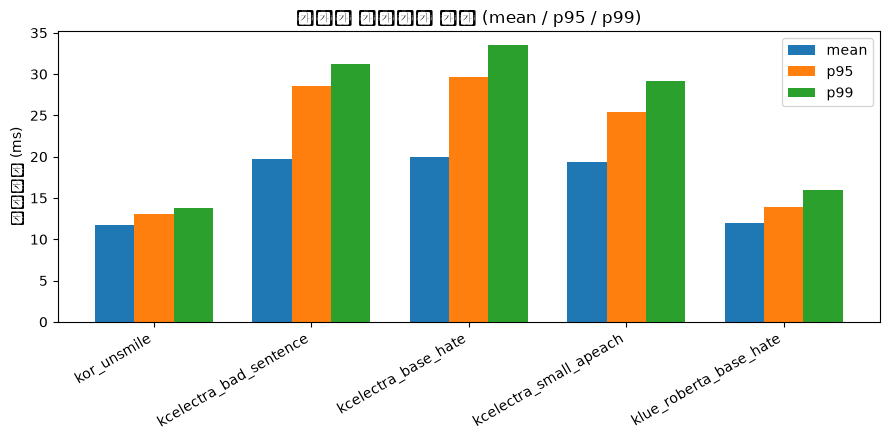

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(results_df))
width = 0.25

ax.bar([i - width for i in x], results_df["mean_latency_ms"], width=width, label="mean")
ax.bar(list(x), results_df["p95_latency_ms"], width=width, label="p95")
ax.bar([i + width for i in x], results_df["p99_latency_ms"], width=width, label="p99")

ax.set_xticks(list(x))
ax.set_xticklabels(results_df["model"], rotation=30, ha="right")
ax.set_ylabel("지연시간 (ms)")
ax.set_title("모델별 지연시간 비교 (mean / p95 / p99)")
ax.legend()
fig.tight_layout()
plt.show()

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_39376\1988250907.py:13: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing f

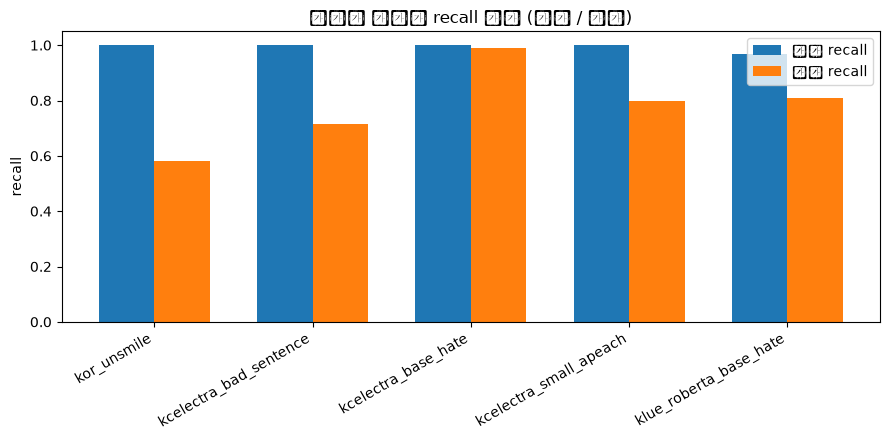

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.35

ax.bar([i - width / 2 for i in x], results_df["recall_정상"], width=width, label="정상 recall")
ax.bar([i + width / 2 for i in x], results_df["recall_악성"], width=width, label="악성 recall")

ax.set_xticks(list(x))
ax.set_xticklabels(results_df["model"], rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("recall")
ax.set_title("모델별 클래스 recall 비교 (정상 / 악성)")
ax.legend()
fig.tight_layout()
plt.show()

## 5. 결론

- **지연시간 목표(검증문서 게이트 기준 수백 ms 이내)를 만족하는 후보:** 5개 전부 만족한다.
  mean 11.7~20.0ms, p99도 최대 33.5ms(`kcelectra_base_hate`)로 목표치와 자릿수 차이가 나서, 이번
  샘플 규모에서는 지연시간이 후보를 가르는 기준이 되지 못한다(다만 노트북 안내대로 210건으로는
  p95/p99 자체가 통계적으로 불안정하다는 점은 유효).
- **정확도/클래스별 recall(특히 악성 recall)이 가장 좋은 후보:** `kcelectra_base_hate`가 압도적이다 —
  accuracy 99.5%, 악성 recall 98.8%(83/84), 정상 recall 100%(오탐 없음). 현재 baseline인
  `kor_unsmile`은 악성 recall이 58.3%(49/84)로 가장 낮다 — 이번 샘플에 넣은 초성체/띄어쓰기/웃음
  접미사 우회 패턴을 절반 가까이 놓친다는 뜻이다. 나머지는 그 사이: `klue_roberta_base_hate`
  81.0%(다만 정상 recall도 96.8%로 유일하게 100% 밑으로 떨어져 오탐이 생기기 시작함),
  `kcelectra_small_apeach` 79.8%, `kcelectra_bad_sentence` 71.4%.
  - `kcelectra_bad_sentence`는 현재 `model_registry.CLASSIFIER_MODELS`에 등록만 돼 있고 baseline
    (`ACTIVE_CLASSIFIER`)은 아닌 `kor_unsmile`이다 — 위 최저 recall은 그 `kor_unsmile` 기준이다.
- **로드 시간·메모리 사용량 관점에서 우려되는 후보:** baseline `kor_unsmile`(로드 2.87s, 6.9MB) 대비
  4개 후보 전부 로드 시간이 크게 늘어난다. 특히 `klue_roberta_base_hate`(83.08s, 60.5MB로 메모리도
  최대)와 `kcelectra_base_hate`(71.89s)가 baseline의 25~29배다. `kcelectra_small_apeach`도 이름과
  달리 로드 23.28s로 짧지 않고 peak_mem(40.3MB)은 두 `kcelectra_*` 파생 모델보다도 크다. 다만 이건
  전부 1회성 기동 비용이고 추론 지연시간에는 반영되지 않으므로, 서비스 기동 방식(요청마다 재로드하는지
  vs 상주 프로세스인지)에 따라 실제 영향 여부가 갈린다.
- **최종 추천 후보 및 근거:** `kcelectra_base_hate`. 정상 recall 100%(오탐 없음)를 유지하면서 악성
  recall을 baseline 대비 58.3% → 98.8%로 크게 끌어올리고, 추론 지연시간(mean 20.0ms, p99 33.5ms)은
  다른 후보들과 비슷한 수준으로 여전히 목표치에 여유가 크다. 로드 시간(71.89s)이 baseline보다 길지만
  상주 서비스라면 1회성 비용이라 recall 개선폭에 비해 감수할 만하다.
- **후속 조치:** (1) 지금 샘플은 실제 방송 채팅 로그가 아니라 손으로 만든 우회 패턴 기반 합성
  데이터라, 최소 200~300건의 실제 로그로 재검증하고 정상:악성 비율(현재 126:84, 3:2)도 실측치로
  다시 맞춰야 한다. (2) 채택을 확정하면 `model_registry.py`의 `ACTIVE_CLASSIFIER`를
  `"kcelectra_base_hate"`로 갱신하고, `chat_agent.ipynb` 3~4번 섹션(현재 `kor_unsmile_plus_rule`
  전략 기준 정확도 비교)도 새 baseline으로 다시 실행해서 파급 효과를 확인한다.